# Mixed-effects model: did water quality change after dam removal?

Reads the outputs of `analysis/mixed_model.py` (run it first: `sbatch data/slurm/fit_mixed_model.slurm` on the cluster, or locally `python analysis/mixed_model.py --case-study all_removals --input analysis_measurement_all_removals.csv`). The notebook doesn't fit anything itself, so it opens in seconds.

## The model in plain English

**The question:** after a dam is removed, does the water downstream change, *beyond what would have changed anyway*?

**The data going in** (same rules as `analysis_robustness.ipynb`):
- **treated** stations: downstream of the dam, and this dam is the measurement's only (or clearly nearest) upstream removal;
- **control** stations: upstream of the same dam, not affected by another removal, and not in the former reservoir;
- one value per station per day (the median), so a logger reading every 15 minutes doesn't count as hundreds of samples;
- skewed parameters (turbidity, conductance, nutrients, TDS) on a log10 scale, so effects read as **% change**.

**Two models per parameter:**

| Model | Uses | Formula | The effect is… |
|---|---|---|---|
| **before/after** | treated stations only | `y ~ post + month + air temp + prior-month rain` | `post`: the average change downstream after removal |
| **BACI** (before-after-control-impact) | dams with both treated *and* control stations | `y ~ post + downstream + post×downstream + month + air temp + prior-month rain` | `post×downstream`: the downstream change **minus** the upstream change at the same dam |

BACI is the stronger design: if a drought or a new treatment plant changes the whole river, upstream changes too and BACI subtracts it out. Before/after has ~5× more dams but can't tell a removal from a regional trend.

**What "mixed effects" adds (the random effects):** every dam gets its *own* baseline level and its *own* removal effect, and every station its own baseline. The headline number is the **average effect across dams**, and its uncertainty reflects how much dams *disagree*, not how many samples there are. That's the fix for the earlier preview models in `analysis_eda`, whose intervals were too narrow because 10,000 samples from 100 dams were treated as 10,000 independent pieces of evidence.

`month`, air temperature and prior-month rain soak up seasonal and weather differences between the before and after samples.

In [1]:
from pathlib import Path
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Project root: the nearest folder at or above this one with etl/ and config/
# (works from any notebooks/ subfolder).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "etl").is_dir() and (p / "config").is_dir())
sys.path.insert(0, str(ROOT))

from analysis import mixed_model as mm

DATA_ROOT = Path(os.environ.get("DAM_REMOVAL_PROJECT_ROOT", ROOT))
CASE_STUDY = "all_removals"
RESULTS_DIR = mm.output_dir_for(CASE_STUDY, DATA_ROOT)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

MODEL_LABELS = {"baci": "BACI (vs upstream)", "before_after": "before/after (downstream)"}
MODEL_STYLE = {"baci": {"color": "#2a78d6", "marker": "o"},
               "before_after": {"color": "#eb6834", "marker": "s"}}
CHECK_SERIES = "dissolved_oxygen"   # series whose residuals section 4 plots

if not (RESULTS_DIR / "results.csv").exists():
    raise FileNotFoundError(f"No model outputs in {RESULTS_DIR}: run analysis/mixed_model.py first.")
results = pd.read_csv(RESULTS_DIR / "results.csv")
dam_effects = pd.read_csv(RESULTS_DIR / "dam_effects.csv")
residuals = pd.read_parquet(RESULTS_DIR / "residuals.parquet")
settings = json.loads((RESULTS_DIR / "settings.json").read_text())
SERIES = [s for s in settings["series"] if s in set(results["series"])]

print(f"Input: {settings['input']}")
for model, formula in settings["formulas"].items():
    print(f"{model:>13}: {formula}   (+ random effects by dam and station)")

Input: /courses/DS5500.202710/teams/team4/data/warehouse/all_removals/analysis_measurement.parquet
 before_after: y ~ post + C(month) + z_air_temp_mean_c + z_precip_prev_month_mm   (+ random effects by dam and station)
         baci: y ~ post + downstream + post_downstream + C(month) + z_air_temp_mean_c + z_precip_prev_month_mm   (+ random effects by dam and station)


## 1. The headline table

One row per parameter and model. Read it like this:
- **effect**: the average change across dams, with its 95% interval. For log-scale parameters it's a % change (+20% = 1.2× higher after removal); otherwise it's in the parameter's unit.
- **verdict**: `higher after` / `lower after` when the whole interval is on one side of 0; otherwise `no clear change`. "No clear change" doesn't mean "no change": with few dams the interval can be wide.
- **dams**: how many dams the estimate rests on. Below ~15, treat it as a hint.
- **fit_check**: `check` means the optimizer flagged the fit (usually harmless, see section 4); compare that row with the dam-bootstrap estimate in `analysis_robustness.ipynb`.

With 8 parameters × 2 models, about 1 interval in 20 excludes 0 by chance alone, so a single "higher/lower" that isn't backed by the other model or by `analysis_robustness` is weak evidence.

In [2]:
def readable(row):
    # The effect and its interval as text, in % for log-scale series.
    if pd.isna(row.get("estimate")):
        return "not fit: " + str(row.get("error", ""))
    if row["log_scale"]:
        return f"{row['pct_estimate']:+.1f}% [{row['pct_ci_low']:+.1f}, {row['pct_ci_high']:+.1f}]"
    unit = row["unit"]
    return f"{row['estimate']:+.3f} [{row['ci_low']:+.3f}, {row['ci_high']:+.3f}] {unit}"


def verdict(row):
    if pd.isna(row.get("estimate")):
        return ""
    if row["ci_low"] > 0:
        return "higher after"
    if row["ci_high"] < 0:
        return "lower after"
    return "no clear change"


table = results.assign(effect=results.apply(readable, axis=1),
                       verdict=results.apply(verdict, axis=1),
                       model=results["model"].map(MODEL_LABELS))
table = table[["series", "model", "effect", "verdict", "p_value", "dams", "stations", "days", "fit_check"]]
table.round({"p_value": 3}).set_index(["series", "model"])

effect          verdict  p_value  dams  stations   days fit_check
series                     model                                                                                                                  
water_temp                 before/after (downstream)      -0.096 [-0.242, +0.051] deg C  no clear change    0.200   144     192.0  13871        ok
                           BACI (vs upstream)             +0.120 [-0.254, +0.495] deg C  no clear change    0.516    29      96.0   6941        ok
dissolved_oxygen           before/after (downstream)       +0.187 [+0.031, +0.342] mg/L     higher after    0.019   138     185.0  12528        ok
                           BACI (vs upstream)              +0.324 [-0.088, +0.736] mg/L  no clear change    0.118    28      91.0   6464        ok
ph                         before/after (downstream)  +0.032 [-0.011, +0.075] std units  no clear change    0.142   141     190.0  12794        ok
                           BACI (vs upstream)         +0.093 [+0.020, +0.167] std units     higher after    0.014    27      95.0   6295        ok
specific_conductance       before/after (downstream)                 +2.2% [-0.2, +4.8]  no clear change    0.076   119     158.0  11374        ok
                           BACI (vs upstream)                        +2.1% [-4.0, +8.6]  no clear change    0.485    19      68.0   4591        ok
turbidity                  before/after (downstream)               -0.3% [-13.1, +14.4]  no clear change    0.967    69      86.0   5895        ok
                           BACI (vs upstream)                     +44.4% [-4.5, +118.2]  no clear change    0.076    12      45.0   3245        ok
phosphorus (Total)         before/after (downstream)                 -3.2% [-8.8, +2.7]  no clear change    0.279    83      99.0   7800        ok
                           BACI (vs upstream)                       -4.6% [-15.4, +7.7]  no clear change    0.413    12      34.0   4495     check
orthophosphate (Dissolved) before/after (downstream)               -22.4% [-35.7, -6.3]      lower after    0.010    37      42.0   3992        ok
                           BACI (vs upstream)                     -17.3% [-57.3, +60.2]  no clear change    0.470     5      14.0   1233     check
tds                        before/after (downstream)                +5.5% [-8.8, +22.2]  no clear change    0.461    44      56.0   3772     check
                           BACI (vs upstream)                not fit: fewer than 5 dams                       NaN     4       NaN    881       NaN

## 2. All effects at a glance

Each panel is one parameter, in its own unit (log-scale ones in %). A dot is the average effect across dams, the bar its 95% interval, and the gray line is "no change". **An interval crossing the gray line is no clear evidence of a change.** Where both models agree in direction, the result is more believable.

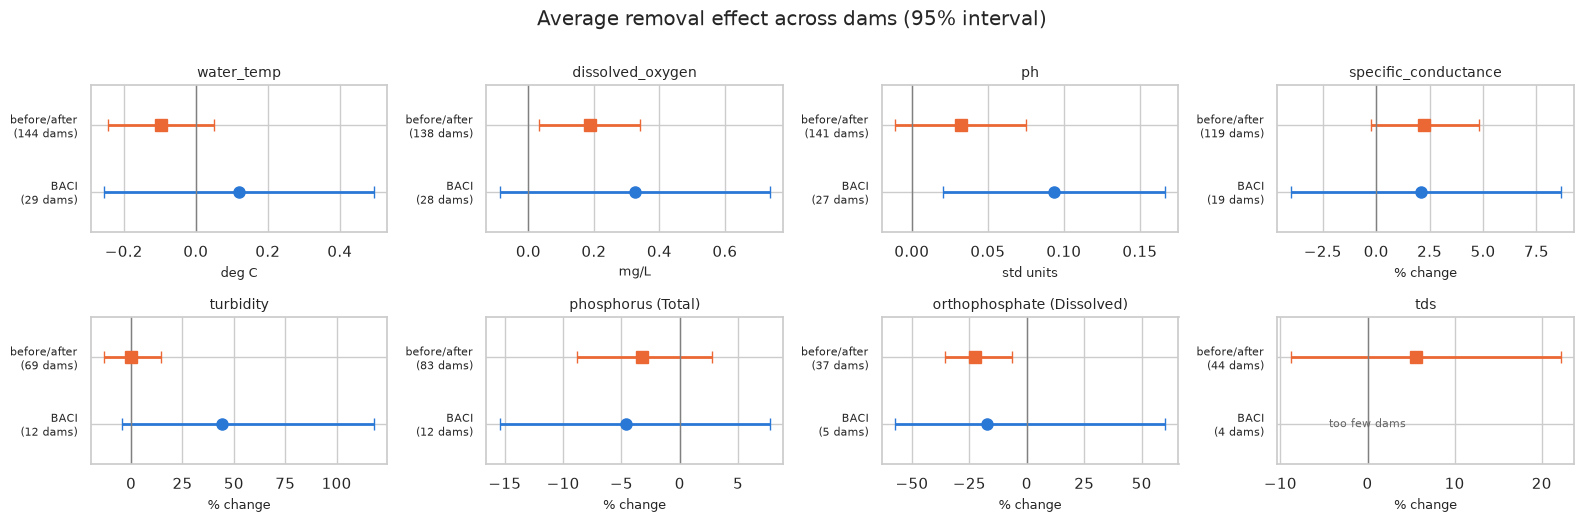

In [3]:
def to_plot_scale(row, key):
    return row[f"pct_{key}"] if row["log_scale"] else row[key]


fig, axes = plt.subplots(2, -(-len(SERIES) // 2), figsize=(4 * -(-len(SERIES) // 2), 5.2), squeeze=False)
for ax in axes.flat[len(SERIES):]:
    ax.set_visible(False)
for ax, series in zip(axes.flat, SERIES):
    r = results[results["series"] == series].set_index("model")
    for i, model in enumerate(["baci", "before_after"]):
        if model not in r.index or pd.isna(r.loc[model, "estimate"]):
            ax.text(0, i, "too few dams", ha="center", va="center", fontsize=8, color="0.4")
            continue
        row = r.loc[model]
        est, low, high = (to_plot_scale(row, k) for k in ["estimate", "ci_low", "ci_high"])
        ax.errorbar(est, i, xerr=[[est - low], [high - est]], fmt=MODEL_STYLE[model]["marker"],
                    color=MODEL_STYLE[model]["color"], ms=8, lw=2, capsize=4)
    ax.axvline(0, color="0.5", lw=1)
    ax.set_yticks([0, 1])
    ax.set_yticklabels([f"{MODEL_LABELS[m].split(' ')[0]}\n({int(r.loc[m, 'dams']) if m in r.index else 0} dams)"
                        for m in ["baci", "before_after"]], fontsize=8)
    ax.set_ylim(-0.6, 1.6)
    log_scale = bool(r["log_scale"].dropna().iloc[0]) if r["log_scale"].notna().any() else False
    ax.set_xlabel("% change" if log_scale else r["unit"].dropna().iloc[0], fontsize=9)
    ax.set_title(series, fontsize=10)
fig.suptitle("Average removal effect across dams (95% interval)", y=1.0)
fig.tight_layout()
plt.show()

## 3. Do the dams agree?

The average can hide a lot: half the dams could go up and half down. Each dot below is **one dam's own estimated effect** (the average plus that dam's random effect). Dams with little data are pulled toward the average ("shrinkage"), so extreme dots are dams with plenty of data.

- A tight cloud on one side of 0: a consistent effect.
- A wide cloud straddling 0: dams differ. Look for what distinguishes the up dams from the down dams (dam height, distance, region) before calling it a removal effect. `time_and_modifier_results.ipynb` (section 8) tests this systematically.

The text gives the share of dams with a positive effect. Each panel is zoomed to the bulk of the dams; a note says how many extreme ones are off scale (they're in the table below the plot). `effect_sd_between_dams` in `results.csv` is the same spread as one number.

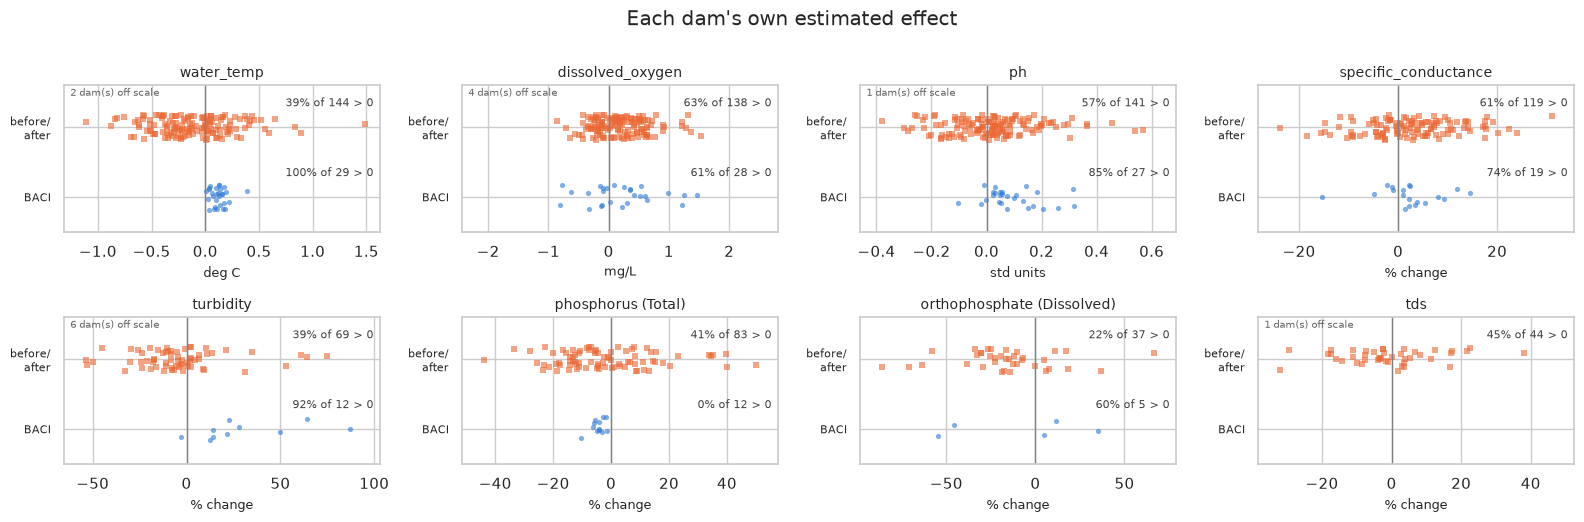

In [4]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, -(-len(SERIES) // 2), figsize=(4 * -(-len(SERIES) // 2), 5.2), squeeze=False)
for ax in axes.flat[len(SERIES):]:
    ax.set_visible(False)
for ax, series in zip(axes.flat, SERIES):
    log_scale = series.split(" (")[0] in settings["log_parameters"]
    shown = []
    for i, model in enumerate(["baci", "before_after"]):
        d = dam_effects[(dam_effects["series"] == series) & (dam_effects["model"] == model)]
        if d.empty:
            continue
        x = (10 ** d["dam_effect"] - 1) * 100 if log_scale else d["dam_effect"]
        shown.append(x)
        ax.scatter(x, i + rng.uniform(-0.18, 0.18, len(d)), s=14, alpha=0.6,
                   color=MODEL_STYLE[model]["color"], marker=MODEL_STYLE[model]["marker"], linewidths=0)
        ax.text(0.98, i + 0.3, f"{(d['dam_effect'] > 0).mean():.0%} of {len(d)} > 0",
                transform=ax.get_yaxis_transform(), ha="right", fontsize=8, color="0.25")
    if shown:
        # Zoom to the bulk (3 IQRs beyond the quartiles) so one extreme dam doesn't flatten the rest.
        x = pd.concat(shown)
        q1, q3 = np.percentile(x, [25, 75])
        low, high = max(x.min(), q1 - 3 * (q3 - q1)), min(x.max(), q3 + 3 * (q3 - q1))
        pad = 0.08 * (high - low or 1)
        ax.set_xlim(min(low, 0) - pad, max(high, 0) + pad)
        if n_out := int(((x < low) | (x > high)).sum()):
            ax.text(0.02, 1.45, f"{n_out} dam(s) off scale", transform=ax.get_yaxis_transform(),
                    fontsize=7, color="0.4")
    ax.axvline(0, color="0.5", lw=1)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["BACI", "before/\nafter"], fontsize=8)
    ax.set_ylim(-0.5, 1.6)
    ax.set_xlabel("% change" if log_scale else mm.unit_label(series, False), fontsize=9)
    ax.set_title(series, fontsize=10)
fig.suptitle("Each dam's own estimated effect", y=1.0)
fig.tight_layout()
plt.show()

In [5]:
# The dams with the largest effects (before/after) for one series, to look up by AR_ID.
d = dam_effects[(dam_effects["series"] == CHECK_SERIES) & (dam_effects["model"] == "before_after")]
pd.concat([d.nlargest(5, "dam_effect"), d.nsmallest(5, "dam_effect")]).round(3)

,AR_ID,dam_effect,days,stations,series,model
262,PA-179,3.265,166,1,dissolved_oxygen,before_after
286,VA-005,3.243,136,3,dissolved_oxygen,before_after
306,WI-127,1.532,82,2,dissolved_oxygen,before_after
258,PA-150,1.364,87,2,dissolved_oxygen,before_after
251,PA-072,1.311,21,1,dissolved_oxygen,before_after
298,WA-031,-5.554,70,1,dissolved_oxygen,before_after
284,TN-033,-0.860,34,1,dissolved_oxygen,before_after
189,IL-022,-0.713,73,1,dissolved_oxygen,before_after
194,MA-032,-0.649,305,4,dissolved_oxygen,before_after
310,WI-151,-0.559,84,1,dissolved_oxygen,before_after


## 4. Can we trust the fits?

**Fit table.** `re_structure` is the random-effects structure that was fit: `dam slopes + station intercepts` is the full model; `dam slopes` means the station term had to be dropped to fit. `fit_check = check` means the optimizer reported a Hessian that isn't positive definite. That almost always comes with a random effect whose variance is estimated at 0 (e.g. dams don't differ in that respect), which doesn't bias the effect. But compare those rows with `analysis_robustness.ipynb` before quoting them. `rows_dropped_missing` counts daily values without climate data.

In [6]:
results[["series", "model", "re_structure", "fit_check", "dams", "days", "rows_dropped_missing",
         "effect_sd_between_dams", "warnings", "error"]].fillna("")

,series,model,re_structure,fit_check,dams,days,rows_dropped_missing,effect_sd_between_dams,warnings,error
0,water_temp,before_after,dam slopes + station intercepts,ok,144,13871,100,0.598805,,
1,water_temp,baci,dam slopes + station intercepts,ok,29,6941,34,0.08627,Maximum Likelihood optimization failed to conv...,
2,dissolved_oxygen,before_after,dam slopes + station intercepts,ok,138,12528,93,0.832001,,
3,dissolved_oxygen,baci,dam slopes + station intercepts,ok,28,6464,32,0.928009,,
4,ph,before_after,dam slopes + station intercepts,ok,141,12794,98,0.234948,,
5,ph,baci,dam slopes + station intercepts,ok,27,6295,32,0.133703,,
6,specific_conductance,before_after,dam slopes + station intercepts,ok,119,11374,83,0.048189,The MLE may be on the boundary of the paramete...,
7,specific_conductance,baci,dam slopes + station intercepts,ok,19,4591,28,0.03804,The MLE may be on the boundary of the paramete...,
8,turbidity,before_after,dam slopes + station intercepts,ok,69,5895,47,0.201735,,
9,turbidity,baci,dam slopes + station intercepts,ok,12,3245,18,0.188455,,


**Residuals** (what the model doesn't explain) for `CHECK_SERIES`. What to look for:
- **left, residuals vs fitted**: a shapeless cloud around 0 is good; a funnel or curve means the scale is wrong (e.g. the parameter should be log-scaled);
- **middle, histogram**: roughly bell-shaped is fine; long tails mean a few outliers carry weight;
- **right, by group**: all four boxes centred on 0. If treated-after sits off 0, the model is missing something about the removal period.

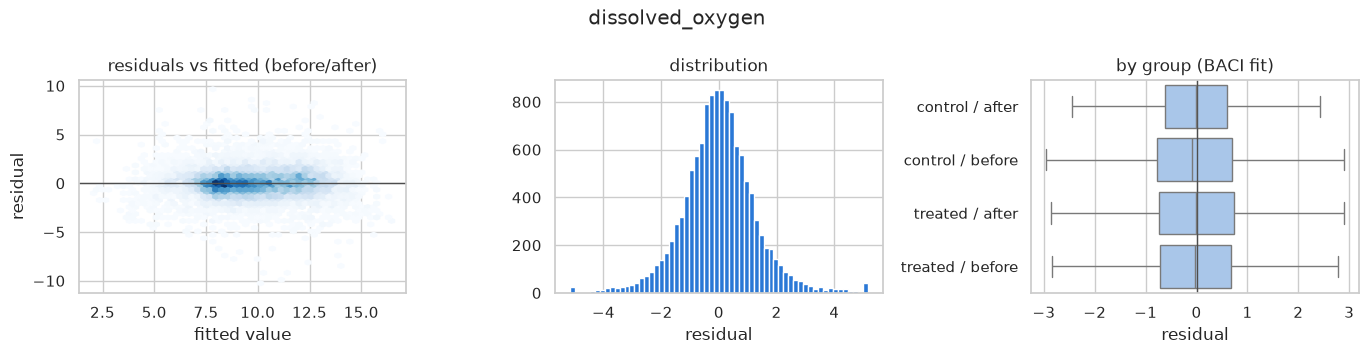

In [7]:
r = residuals[(residuals["series"] == CHECK_SERIES) & (residuals["model"] == "before_after")]
if r.empty:
    print(f"No residuals for {CHECK_SERIES}")
else:
    both = residuals[(residuals["series"] == CHECK_SERIES) & (residuals["model"] == "baci")]
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    axes[0].hexbin(r["fitted"], r["residual"], gridsize=50, cmap="Blues", mincnt=1)
    axes[0].axhline(0, color="0.3", lw=1)
    axes[0].set(xlabel="fitted value", ylabel="residual", title="residuals vs fitted (before/after)")
    lim = np.nanpercentile(np.abs(r["residual"]), 99.5)
    axes[1].hist(r["residual"].clip(-lim, lim), bins=60, color="#2a78d6")
    axes[1].set(xlabel="residual", title="distribution")
    groups = (both if len(both) else r).assign(
        group=lambda g: g["role"] + " / " + np.where(g["post"] == 1, "after", "before"))
    order = sorted(groups["group"].unique())
    sns.boxplot(data=groups, x="residual", y="group", order=order, ax=axes[2], showfliers=False,
                color="#9ec5f4")
    axes[2].axvline(0, color="0.3", lw=1)
    axes[2].set(title="by group (BACI fit)" if len(both) else "by group", ylabel="")
    fig.suptitle(CHECK_SERIES)
    fig.tight_layout()
    plt.show()

## 5. How to read this, and what it can't tell you

- **Lead with BACI** where it has ~15+ dams; use before/after as supporting evidence. An effect that shows in both models, in section 3's dam cloud, *and* in `analysis_robustness.ipynb`'s BACI is the strongest claim these data support.
- **Direction expected for small-dam removals:** cooler water and more dissolved oxygen downstream (no warm, still reservoir), turbidity and phosphorus up briefly while sediment moves. Effects in the 1–5 years after removal are an average over that whole window; `time_and_modifier_results.ipynb` shows year 1, years 2–3 and years 4–5 separately.
- **Not in the model:** stream flow (wet vs dry years beyond rain), dams still standing between a station and the removal (not in the data), censoring (non-detects are half the detection limit), and changes in method or turbidity unit across the removal (checked in `analysis_robustness` section 3).
- **Association, not proof.** The model compares before with after, and downstream with upstream, at removed dams; it can't rule out something else that happened at the same time and place.

## 6. Changing the model

Everything a design change touches is in `SETTINGS` at the top of `analysis/mixed_model.py`; rerun the script and this notebook picks up the new outputs.

| To… | Change |
|---|---|
| model other parameters | `SETTINGS["series"]` (or `--series` on the command line) |
| change who counts as treated / control | `treated_exposure`, `control_exposure`, `exclude_former_reservoir` |
| drop flagged stations (e.g. saline) | `exclude_flags = ["qc_saline"]` |
| add or remove covariates | `covariates` (any numeric column of `analysis_measurement`) |
| require more dams | `min_dams` |
| ask whether the effect depends on a dam characteristic (dam height, reservoir size, land cover, …) or changes with years since removal | already built in `analysis/distance_models.py` (designs 11–12; `docs/time_and_modifier_models.md`); results in `time_and_modifier_results.ipynb` |

A rebuilt `analysis_measurement` (new distance limits, eligibility rules, more dams) needs no code change, only a rerun. The script stops with a clear message if a column it needs (`REQUIRED_COLUMNS`) is gone.

## 7. Sensitivity: a looser eligibility rule (3 samples, 1 year)

The same two models refit on stations with **at least 3 samples in at least 1 year** per side (*3 / 1*), and with **2 different months** required when a side has one year (*3 / 1, ≥2 months*), instead of 3 samples in 2 years. Pre-specified in `docs/eligibility_sensitivity_prespec.md`; the results above stay the main results. Labels: **robust** (same verdict and direction), **sharper** (main inconclusive → decided), **weaker** (main decided → inconclusive), **conflicting**, **direction unstable**. Verdicts use the same "too small to matter" thresholds as the distance models.

Models with **fewer than 10 dams** on either side are shown but not compared (the pre-specified minimum; the mixed models themselves are fit from 5 dams). **Clarification made 2026-11-08, after these results were seen:** when both estimates are *no meaningful change* (both 95% ranges inside the threshold), the comparison is **robust** even if the signs differ; `negligible_sign_flip` marks those rows. Nothing else about the labels, estimates or thresholds changed (`docs/eligibility_sensitivity_prespec.md`).

In [ ]:
from analysis import sensitivity_compare as sc
from analysis import stage4_report as rep

sens = {}
for label, variant in {"3 / 1": "min1yr", "3 / 1, ≥2 months": "min1yr_2mo"}.items():
    path = RESULTS_DIR / f"sensitivity_{variant}" / "mixed_model" / "results.csv"
    if path.exists():
        sens[label] = pd.read_csv(path)
if not sens:
    print("Sensitivity runs not done yet; see docs/eligibility_sensitivity_prespec.md (Procedure) for the commands.")
for label, frame in sens.items():
    t = sc.compare(results, frame, ["series", "model"], "estimate", "ci_low", "ci_high", sesoi=rep.SESOI)
    t["model"] = t["model"].map(MODEL_LABELS)
    print(f"\n{label} vs main (fewer than {sc.MIN_DAMS} dams on either side: shown, not compared):")
    display(t[["model", "series", "dams_primary", "dams_sensitivity", "est_primary", "est_sensitivity",
               "verdict_primary", "verdict_sensitivity", "label", "negligible_sign_flip", "ci_width_ratio",
               "material_improvement"]]
            .sort_values(["model", "series"]).reset_index(drop=True))

### 7b. Why is the before/after specific-conductance range 4× wider under 3 / 1?

Under 3 / 1 the before/after specific-conductance model has 27 more dams but a 95% range about 4 times as wide (the distance model for the same measure doesn't widen). This section looks for the cause. **It changes nothing:** the reported models stay as they are, and the refits below are diagnostics only (a few seconds each, on the same rows and the same model code).

1. The fit itself, main vs 3 / 1: random-effects structure, fit check, and how much the effect varies between dams (`effect_sd_between_dams`). A wider range with more dams usually means that SD went up.
2. Each dam's own effect: are a few **added** dams far from the rest?
3. Those dams' data: raw conductance before and after, and the **saline flag** (`qc_saline`: the station's median conductance is above 3,000 µS/cm). Saline stations are flagged but **not excluded** in any model.
4. Diagnostic refits: without saline-flagged stations, and without the 1–5 most extreme added dams.

In [ ]:
INV_SERIES, INV_MODEL, INV_VARIANT = "specific_conductance", "before_after", "min1yr"
inv_dir = RESULTS_DIR / f"sensitivity_{INV_VARIANT}" / "mixed_model"
if not (inv_dir / "results.csv").exists():
    raise FileNotFoundError(f"No sensitivity outputs in {inv_dir}")
s_results = pd.read_csv(inv_dir / "results.csv")
s_effects = pd.read_csv(inv_dir / "dam_effects.csv")
s_settings = json.loads((inv_dir / "settings.json").read_text())

def pick(frame):
    return frame[(frame["series"] == INV_SERIES) & (frame["model"] == INV_MODEL)]

fit_cols = ["dams", "stations", "days", "estimate", "se", "ci_low", "ci_high", "pct_estimate", "pct_ci_low",
            "pct_ci_high", "effect_sd_between_dams", "re_structure", "fit_check", "warnings"]
fits = pd.concat({"main (3 / 2)": pick(results).iloc[0], "3 / 1": pick(s_results).iloc[0]}, axis=1)
display(fits.reindex([c for c in fit_cols if c in fits.index]))

p_eff = pick(dam_effects).assign(AR_ID=lambda f: f["AR_ID"].astype(str))
s_eff = pick(s_effects).assign(AR_ID=lambda f: f["AR_ID"].astype(str))
s_eff["group"] = np.where(s_eff["AR_ID"].isin(p_eff["AR_ID"]), "main dams", "added under 3 / 1")
print("Dam effects (log10 units; the average plus each dam's random slope):")
display(s_eff.groupby("group")["dam_effect"].describe(percentiles=[0.05, 0.5, 0.95]))
same = s_eff.merge(p_eff[["AR_ID", "dam_effect"]], on="AR_ID", suffixes=("", "_main"))
print(f"Main dams: correlation of their effect under 3 / 2 vs 3 / 1 = "
      f"{same['dam_effect'].corr(same['dam_effect_main']):.2f} ({len(same)} dams)")

fig, ax = plt.subplots(figsize=(8, 2.6))
for i, (g, d) in enumerate(s_eff.groupby("group")):
    ax.scatter(d["dam_effect"], np.full(len(d), i) + rng.uniform(-0.15, 0.15, len(d)), s=12, alpha=0.6)
ax.set_yticks(range(s_eff["group"].nunique()), sorted(s_eff["group"].unique()))
ax.axvline(0, color="0.5", lw=0.8); ax.set_xlabel("dam effect (log10 µS/cm; 0.1 ≈ +26%)")
ax.set_title(f"{INV_SERIES}, {INV_MODEL}, 3 / 1: each dam's effect"); fig.tight_layout(); plt.show()

In [ ]:
# The exact rows the 3 / 1 model was fit on (same code and settings), plus the saline flag.
inv_settings = dict(mm.SETTINGS, series=[INV_SERIES], carry_columns=["qc_saline"])
inv_input = Path(s_settings["input"])
inv_input = inv_input if inv_input.is_absolute() else DATA_ROOT / inv_input
daily = mm.prepare(mm.read_measurements(inv_input, inv_settings), inv_settings)
rows = mm.model_rows(daily[daily["series"] == INV_SERIES], INV_MODEL, inv_settings)
rows = rows.dropna(subset=inv_settings["covariates"]).assign(AR_ID=lambda f: f["AR_ID"].astype(str))
print(f"Rows rebuilt: {rows['AR_ID'].nunique()} dams, {len(rows):,} days "
      f"(the 3 / 1 fit reports {int(pick(s_results)['dams'].iloc[0])} dams, {int(pick(s_results)['days'].iloc[0]):,} days)")

saline = rows["qc_saline"].astype("boolean")
print(f"Saline-flagged: {int(saline.fillna(False).sum()):,} days at {rows.loc[saline.fillna(False), 'station_id'].nunique()} "
      f"stations / {rows.loc[saline.fillna(False), 'AR_ID'].nunique()} dams; flag unknown on {int(saline.isna().sum()):,} days")

per_dam = (rows.assign(us_cm=10 ** rows["y"])
           .groupby("AR_ID")
           .agg(days=("y", "size"), stations=("station_id", "nunique"),
                pre_median_us_cm=("us_cm", lambda v: v[rows.loc[v.index, "post"] == 0].median()),
                post_median_us_cm=("us_cm", lambda v: v[rows.loc[v.index, "post"] == 1].median()),
                max_us_cm=("us_cm", "max"),
                days_pre=("post", lambda v: int((v == 0).sum())), days_post=("post", "sum"),
                saline_days=("qc_saline", lambda v: int(v.fillna(False).astype(bool).sum())))
           .reset_index())
per_dam["raw_log10_change"] = np.log10(per_dam["post_median_us_cm"] / per_dam["pre_median_us_cm"])
per_dam = per_dam.merge(s_eff[["AR_ID", "dam_effect", "group"]], on="AR_ID", how="left")
center = pick(s_results)["estimate"].iloc[0]
per_dam["distance_from_average"] = (per_dam["dam_effect"] - center).abs()
print("\nThe 12 dams furthest from the average effect (3 / 1):")
display(per_dam.sort_values("distance_from_average", ascending=False).head(12).round(3))
print("Saline-flagged dams:")
display(per_dam[per_dam["saline_days"] > 0].sort_values("distance_from_average", ascending=False).round(3))

In [ ]:
# Diagnostic refits (not reported results): does the width come from a few dams, or from saline stations?
def refit(subset, what):
    try:
        res, re_structure, warn = mm.fit_model(subset, INV_MODEL, inv_settings)
    except RuntimeError as exc:
        return {"refit": what, "error": str(exc)[:120]}
    row = mm.summarize(res, subset, INV_SERIES, INV_MODEL, re_structure, warn, 0)
    return {"refit": what, **{k: row[k] for k in ("dams", "days", "estimate", "ci_low", "ci_high",
                                                  "effect_sd_between_dams", "re_structure", "fit_check")}}

main_width = float(pick(results)["ci_high"].iloc[0] - pick(results)["ci_low"].iloc[0])
added = per_dam[per_dam["group"] == "added under 3 / 1"].sort_values("distance_from_average", ascending=False)
checks = [refit(rows, "3 / 1, all rows (should match the reported fit)"),
          refit(rows[~rows["qc_saline"].fillna(False).astype(bool)], "3 / 1 without saline-flagged stations"),
          refit(rows[rows["AR_ID"].isin(p_eff["AR_ID"])], "3 / 1 rows, main dams only")]
for k in range(1, 6):
    drop = set(added["AR_ID"].head(k))
    checks.append(refit(rows[~rows["AR_ID"].isin(drop)], f"3 / 1 without the {k} most extreme added dam(s)"))
checks = pd.DataFrame(checks)
checks["ci_width_vs_main"] = (checks["ci_high"] - checks["ci_low"]) / main_width
print(f"Main (3 / 2) 95% range width: {main_width:.4f} (log10 units). Ratio 1 = as precise as the main model.")
display(checks.round(4))
print("Most extreme added dams, in order:", list(added["AR_ID"].head(5)))

**Reading it.** If dropping one or a few added dams brings the width ratio back near 1, the widening comes from those dams (their conductance changed far more than other dams', which inflates the between-dam SD), not from the looser rule as such. Look them up in the table above: a saline flag, a very high conductance or very few days on one side point to an unusual site. If removing saline stations alone fixes it, the unapplied saline flag matters for this measure. If the "main dams only" refit is already wide, the extra *days* at existing dams changed the fit, not the added dams. If the width jumps around between refits that differ by one dam, or a refit shows `fit_check = check` or a much larger `effect_sd_between_dams`, the fit is unstable (the conductance fits report an estimate on the boundary of the parameter space). The 4× range may then be partly a fitting artifact; compare with the distance model for the same measure (`distance_model_results.ipynb` section 11, range ratio 0.90). **Whatever this shows, the reported row stays as fit;** any exclusion would be a new analysis choice, reported as such.

## 8. Sensitivity: BACI with controls known to be outside the former reservoir

An upstream station that sat in the former reservoir is changed by the removal itself, so it isn't a valid control. The main models drop stations flagged as in the former reservoir, but the flag is **unknown** when a dam has no height or slope, and those stations count as controls. This refit keeps only controls **positively known** to be outside (pre-specified in `docs/control_sensitivity_prespec.md`, before any fit). BACI only: before/after has no controls. Same labels, thresholds and 10-dam rule as section 7. Because the setting can only remove controls, BACI dams drop; that loss is itself the measure of how much the BACI evidence rests on unknown-status controls.

In [ ]:
kc_path = RESULTS_DIR / "sensitivity_known_controls" / "mixed_model" / "results.csv"
if not kc_path.exists():
    print("Not run yet: KNOWN_CONTROLS=1 sbatch data/slurm/fit_mixed_model.slurm")
else:
    from analysis import sensitivity_compare as sc
    from analysis import stage4_report as rep
    kc = pd.read_csv(kc_path)
    baci = lambda f: f[f["model"] == "baci"]
    t = sc.compare(baci(results), baci(kc), ["series", "model"], "estimate", "ci_low", "ci_high", sesoi=rep.SESOI)
    t["dams_lost"] = t["dams_primary"].fillna(0) - t["dams_sensitivity"].fillna(0)
    print(f"BACI, main vs controls known outside the reservoir (fewer than {sc.MIN_DAMS} dams: shown, not compared):")
    display(t[["series", "dams_primary", "dams_sensitivity", "dams_lost", "est_primary", "est_sensitivity",
               "verdict_primary", "verdict_sensitivity", "label", "negligible_sign_flip", "ci_width_ratio"]]
            .sort_values("series").reset_index(drop=True))
    print("Labels, counted:")
    display(t["label"].value_counts())

## 9. What could these models detect? (post-hoc design sensitivity)

**Post-hoc design sensitivity, not a pre-specified or prospective power analysis.** Added 2026-11-09, after the results were seen. It uses only the standard errors already in the result files (nothing is refit) and changes no estimate, verdict or threshold. It answers: *given how precise each model turned out to be, how large would a true effect have to be for it to be detected?*

- **MDE80** (minimum detectable effect): the true effect the model would detect (95% interval excluding 0) 80% of the time, = (t₀.₉₇₅ + t₀.₈₀) × SE. For log-scale measures the MDE is a log10 size, shown as the matching % rise / % fall (the same log size is a smaller % fall: +25% ↔ −20%).
- **Power at threshold:** the chance of detecting a true effect **exactly the size of the analyst-selected, provisional "too small to matter" threshold**. It is never computed at the observed estimate (that only restates the p-value). MDE and threshold are on the same scale (log10 for log-scale measures), so **MDE ÷ threshold < 1** ⇔ power at threshold > 80%.
- **Degrees of freedom: dams − 1**, the same as the models' 95% intervals (dams are the independent units). For a mixed model this is an approximation (statsmodels has no Satterthwaite / Kenward–Roger correction); it is likely conservative when the effect is estimated mostly within dams (random intercepts only) and may be optimistic when a few dams carry most of the data (fewer effective dams). The SEs themselves are the models' large-sample SEs.
- **Dams for MDE ≤ threshold** is a **rough projection, not a sample-size requirement**: it assumes the SE shrinks like 1 / √dams and that added dams resemble these (same variances, stations and sampling).
- **Reading it:** an *inconclusive* verdict with low power at threshold means the data were too thin to tell, not that nothing changed. A *detected* verdict doesn't need power to be believed, and low power is not a reason to discount it (though small, low-powered studies tend to overstate the size of what they detect).

These are the 10 km mixed models of section 1 (BACI and before/after). The model's own SE and dam count are used; the MDE uses the same formula as the distance models (`analysis/distance_models.py` `mde()`). Verdicts are classified with the same thresholds as the distance models (section 7).

In [ ]:
from analysis import stage4_report as rep

from scipy import stats
from analysis import distance_models as dm   # mde(), power(), dams_needed()

def is_log(series):
    """Log10 scale, as for the thresholds (stage4_report.sesoi_label)."""
    return pd.Series(series).str.split(" (", regex=False).str[0].isin(mm.SETTINGS["log_parameters"]).to_numpy()

def k80(dams):
    """MDE80 = k80 x SE with dams - 1 df (distance_models.mde), so SE = MDE80 / k80."""
    df = np.maximum(np.asarray(dams, float) - 1, 1)
    return stats.t.ppf(0.975, df) + stats.t.ppf(dm.POWER, df)

def plain_size(value, log_scale, unit=""):
    """A size on the model scale in plain units. Log10: the % rise / % fall of that size."""
    if pd.isna(value):
        return ""
    if log_scale:
        return f"+{(10 ** value - 1) * 100:.0f}% / −{(1 - 10 ** -value) * 100:.0f}%"
    return f"{value:.2g} {unit}".strip()

def needed_text(mde, threshold, dams):
    """Rough projection only (SE shrinking like 1 / sqrt(dams), new dams like these)."""
    if pd.isna(mde) or pd.isna(threshold):
        return ""
    if mde <= threshold:
        return "already ≤ threshold"
    n = dm.dams_needed(mde, threshold, dams)
    return "> 10,000" if np.isinf(n) else f"~{n:,.0f}"

def design_sensitivity(frame, mde=None, se=None):
    """Add threshold, MDE80 (plain units), MDE ÷ threshold, power at the threshold and the
    rough dams projection. Give the MDE80 column or the SE column (model units: log10 for
    log-scale series, the same scale as rep.SESOI)."""
    f = frame.copy()
    thr = f["series"].map(rep.SESOI).astype(float)
    dams = f["dams"].astype(float)
    se_v = f[se].astype(float) if se else f[mde].astype(float) / k80(dams)
    mde_v = f[mde].astype(float) if mde else se_v * k80(dams)
    log = is_log(f["series"])
    unit = f["unit"] if "unit" in f else pd.Series("", index=f.index)
    f["threshold"] = f["series"].map(rep.sesoi_label)
    f["MDE80"] = [plain_size(m, l, u) for m, l, u in zip(mde_v, log, unit.fillna(""))]
    f["MDE ÷ threshold"] = (mde_v / thr).round(2)
    f["power at threshold"] = np.round(dm.power(thr.to_numpy(), se_v.to_numpy(), dams.to_numpy()), 2)
    f["dams for MDE ≤ threshold (rough)"] = [needed_text(m, t, d) for m, t, d in zip(mde_v, thr, dams)]
    return f

fitted = results[results["error"].fillna("").eq("") & results["estimate"].notna()]
md_ = design_sensitivity(fitted, se="se")
md_["verdict"] = [rep.classify(e, lo, hi, rep.SESOI.get(s))
                  for e, lo, hi, s in zip(md_["estimate"], md_["ci_low"], md_["ci_high"], md_["series"])]
md_["model"] = md_["model"].map(MODEL_LABELS)
display(md_[["series", "model", "dams", "verdict", "threshold", "MDE80", "MDE ÷ threshold", "power at threshold",
             "dams for MDE ≤ threshold (rough)"]].sort_values(["model", "MDE ÷ threshold"]).reset_index(drop=True))
p = md_["power at threshold"]
print(f"{int((p >= 0.8).sum())} of {int(p.notna().sum())} models have ≥ 80% power at their threshold; "
      f"{int((p < 0.5).sum())} have < 50%. Models with < 10 dams are shown for completeness.")